In [1]:
import zipfile
from collections import defaultdict
import pandas as pd

import archive_reader as ar


    vocabularies = {
        query: {  # query as string
            corpus_name: {  # path as string
                thread_id: {    # byte
                    lemma: count    # byte: int
                }
            }
        }
    }

In [3]:
queries = ["deradik", "maltillistu", "polaris", "radik"]
suomi24_zip = "suomi24-2001-2017-vrt-v1-3.zip"  # path to zip file

# # get zip archive file names
# with zipfile.ZipFile(suomi24_zip, mode="r") as zf:
#     names = zf.namelist()[0:17]  # include 2001-2017, exclude LICENSE.txt and README.txt
names = ['suomi24-2001-2017-vrt-v1-3/data/s24_2001.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2002.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2003.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2004.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2005.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2006.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2007.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2008.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2009.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2010.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2011.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2012.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2013.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2014.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2015.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2016.vrt', 'suomi24-2001-2017-vrt-v1-3/data/s24_2017.vrt']

# load relevant information with archive_reader
ar.query(queries, suomi24_zip)
# query_json = ar.get_query(queries[0])  # access individual query results
vocabularies = ar.scan(queries, "filtered_queries", suomi24_zip)

03:21: Looking for queries.
03:21: Query results for deradik found: queries/deradik.json
03:21: Query results for maltillistu found: queries/maltillistu.json
03:21: Query results for polaris found: queries/polaris.json
03:21: Query results for radik found: queries/radik.json
03:21: Queries finished.
03:21: Starting Suomi24-corpus scan.
Running scan 0 times. This will take around (6-10 min X 0) / core_count on an SSD. To rerun the same task, delete the .pkl files in scan_tasks/.
03:21: All scans complete.


In [4]:
#query_json = ar.get_query(queries[1], "filtered_queries")  # access individual query results

In [5]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

In [6]:
titles = {}
for q in queries:
    titles[q] = ar.get_unique_titles(q, "filtered_queries")
    
print(f"{queries[0]}: {titles[queries[0]]}")

deradik: defaultdict(<class 'set'>, {'S24_2015': {'Kuinka monta ISIS-taistelijaa on tullut Suomeen?'}, 'S24_2016': {'Yle matujen aialla.'}, 'S24_2017': {'Islamin kieltäminen Suomessa', 'Muitakin ongelmia on kuin maahanmuutto'}})


In [7]:
with open("StopWordsFin.txt", "r", encoding="utf-8") as file:
    finnish_stopwords = {line.strip() for line in file if line.strip()}

In [8]:
from libvoikko import Voikko

v = Voikko("fi")

In [9]:
texts_sorted = {}

for title in titles:
    for year in titles[title]:
        filtered = []

        for sentence in titles[title][year]:
            words = [
                word.strip(".,!?;:").lower()
                for word in sentence.split()
            ]

            for word in words:
                if not word or word in finnish_stopwords:
                    continue

                analyses = v.analyze(word)

                if analyses:
                    lemma = analyses[0]["BASEFORM"]
                else:
                    lemma = word

                if lemma not in finnish_stopwords:
                    filtered.append(lemma)

        texts_sorted[f"{title}_{year}"] = filtered
v.terminate()

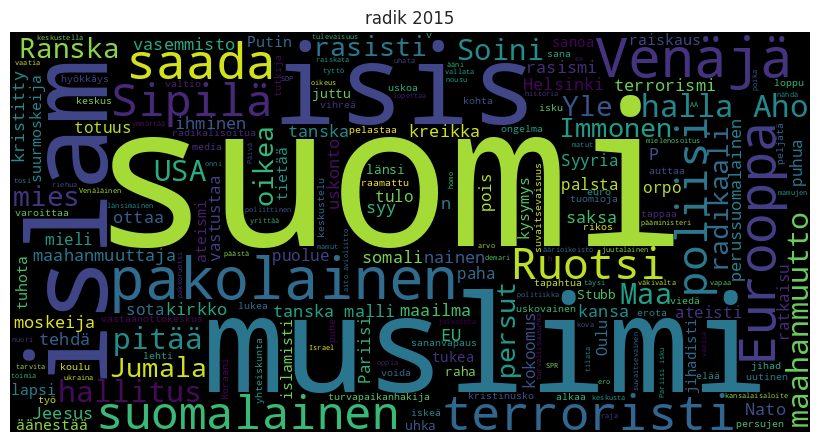

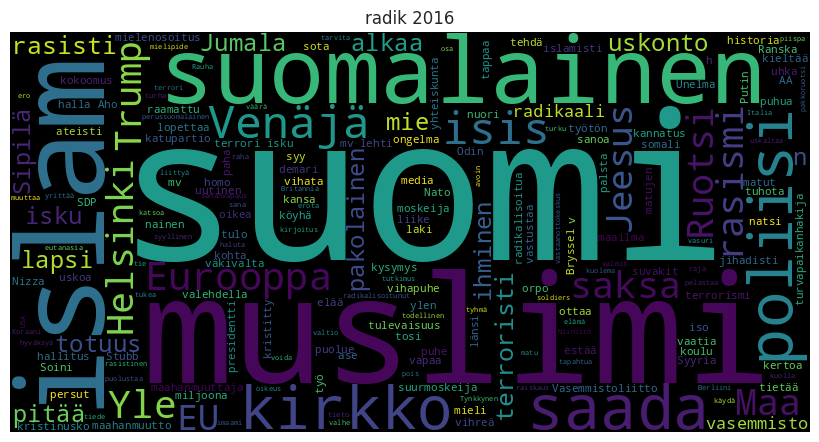

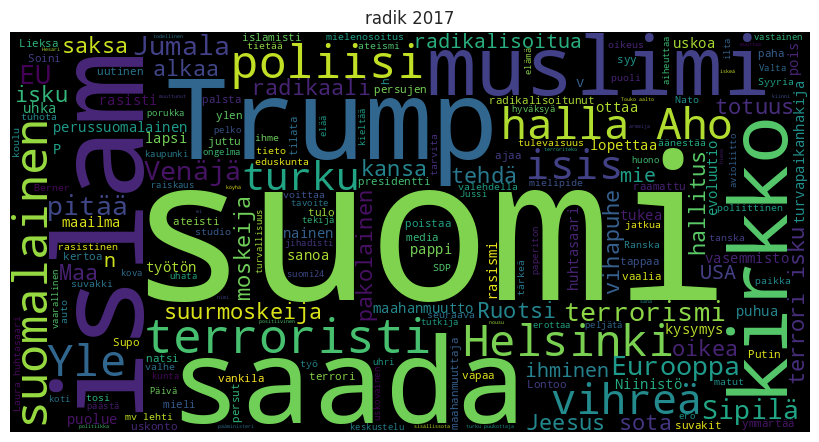

In [10]:
for text, texts in texts_sorted.items():
    if len(texts) < 8000:
        continue
    plt.figure(figsize=(8, 4))
    plt.imshow(WordCloud(width=800, height=400).generate(" ".join(texts_sorted[text])), interpolation="bilinear")
    plt.axis("off")
    plt.tight_layout(pad=0)
    plt.title(text.replace('_S24_', ' '))
    plt.show()

In [11]:
import os

totals = {}

for query, corpora in vocabularies.items():
    for year, threads in corpora.items():
        year = os.path.basename(year).replace("s24_", "").replace(".vrt", "")

        texts = []

        for lemmas in threads.values():
            texts.append(lemmas)

        totals[f"{query}_S24_{year}"] = texts

In [12]:
item = list(totals.keys())[0]

In [13]:
feil = pd.read_csv("FEIL.tsv", sep="\t")

def score_text(word_counts):
    words = [
        word.decode("utf-8") if isinstance(word, bytes) else word
        for word in word_counts.keys()
    ]

    matches = feil[feil["finnish-fi"].isin(words)]

    return matches.groupby("emotion")["emotion-intensity-score"].mean().to_dict()

FileNotFoundError: [Errno 2] No such file or directory: 'FEIL.tsv'

In [ ]:
positive = ['anticipation', 'joy', 'trust']
negative = ['anger', 'disgust', 'fear', 'sadness']

In [ ]:
sentiments = {}

for item, texts in totals.items():
    positive_total = 0
    negative_total = 0
    total_words = 0
    valid_items = False

    for text in texts:
        scores = score_text(text)

        word_count = sum(text.values())
        total_words += word_count

        for emotion, score in scores.items():
            weighted_score = score * word_count

            if emotion in positive:
                positive_total += weighted_score
                valid_items = True
            elif emotion in negative:
                negative_total += weighted_score
                valid_items = True

    if valid_items:
        sentiments[item] = {
            'positive': positive_total / total_words if total_words else 0,
            'negative': negative_total / total_words if total_words else 0
        }

In [ ]:
max_sentiment = max(
    max(values["positive"], values["negative"])
    for values in sentiments.values()
)

sentiments_normalized = {}

for item, values in sentiments.items():
    sentiments_normalized[item] = {
        "positive": values["positive"] / max_sentiment,
        "negative": values["negative"] / max_sentiment
    }

sentiments = sentiments_normalized

In [ ]:
from scipy.stats import pearsonr
from collections import defaultdict

articles = [
    4/575,    #2001
    0/958,    #2002
    1/1080,   #2003
    2/830,    #2004
    1/891,    #2005
    4/2660,   #2006
    6/3170,   #2007
    4/3570,   #2008
    4/10700,  #2009  
    1/14100,  #2010
    75/12400, #2011
    5/12600,  #2012
    35/18600, #2013
    6/21100,  #2014
    41/25200, #2015
    42/21700, #2016
    74/20500, #2017
]


articles = [article/max(articles) for article in articles]

In [ ]:
results = {}

for i, query in enumerate(queries):
    results[query] = ar.get_query_comment_counts(query, "filtered_queries")

print(results)

In [ ]:
fig, axes = plt.subplots(
    nrows=len(results),
    ncols=1,
    figsize=(12, 12),
    sharex=True
)

for ax, (category, counts) in zip(axes, results.items()):
    years = sorted(int(key.split('_')[1]) for key in counts)
    values = [counts[f'S24_{year}'] for year in years]

    ax.plot(years, values, marker='o', linewidth=2)
    ax.set_title(category)
    ax.set_ylabel('Number of hits')
    ax.set_xticks(range(2001, 2018))
    ax.grid(True, alpha=0.3)

axes[-1].set_xlabel('Year')

fig.suptitle('Search hits per year by category', fontsize=15)
plt.tight_layout()
plt.show()


In [ ]:
import numpy as np

article_by_year = dict(zip(range(2001, 2018), articles))

grouped = defaultdict(dict)

for item, values in sentiments.items():
    category, year = item.rsplit("_S24_", 1)
    grouped[category][int(year)] = values

for category, yearly_data in grouped.items():
    years = sorted(set(yearly_data) & set(article_by_year))

    article_values = np.array([article_by_year[y] for y in years])

    positive = np.array([yearly_data[y]["positive"] for y in years])
    negative = np.array([yearly_data[y]["negative"] for y in years])

    total = positive - negative
    polarization = positive + negative

    r, p = pearsonr(positive, negative)
    print(f"{category} pos, neg: r={r:.3f}, p={p:.4f}, n={len(years)}")

    r, p = pearsonr(total, article_values)
    print(f"{category} average: r={r:.3f}, p={p:.4f}, n={len(years)}")

    r, p = pearsonr(polarization, article_values)
    print(f"{category} polarization: r={r:.3f}, p={p:.4f}, n={len(years)}")

    r, p = pearsonr(positive, article_values)
    print(f"{category} positive: r={r:.3f}, p={p:.4f}, n={len(years)}")

    r, p = pearsonr(negative, article_values)
    print(f"{category} negative: r={r:.3f}, p={p:.4f}, n={len(years)}")

In [ ]:
for query, yearly_data in results.items():

    years = sorted(set(yearly_data) & set(
        f"S24_{year}" for year in article_by_year
    ))

    query_values = np.array([yearly_data[y] for y in years])

    article_values = np.array([
        article_by_year[int(y.replace("S24_", ""))]
        for y in years
    ])

    if len(years) < 3:
        continue

    r, p = pearsonr(query_values, article_values)

    print(f"{query}: r={r:.3f}, p={p:.4f}, n={len(years)}")

In [ ]:
import re

In [ ]:
rows = []

for item, scores in sentiments.items():
    match = re.match(r"(.+)_(\d{4})$", item)

    if match:
        company = match.group(1)
        year = int(match.group(2))

        for term, score in scores.items():
            rows.append({
                "company": company,
                "year": year,
                "term": term,
                "score": score
            })

df = pd.DataFrame(rows)

for company in sorted(df["company"].unique()):
    company_df = df[df["company"] == company]

    plt.figure(figsize=(10, 5))

    for term in sorted(company_df["term"].unique()):
        term_df = company_df[company_df["term"] == term].sort_values("year")

        plt.plot(
            term_df["year"],
            term_df["score"],
            marker="o",
            label=term
        )

    plt.title(f"{company.replace('_S24', '')}")
    plt.xlabel("Year")
    plt.ylabel("Sentiment score")
    plt.xticks(sorted(company_df["year"].unique()))
    plt.legend(title="Sentiment")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

In [ ]:
from collections import Counter

v = Voikko("fi")

word_counts = defaultdict(Counter)

for item, texts in totals.items():

    category, year = item.rsplit("_S24_", 1)
    key = (category, int(year))

    for text in texts:
        for word, count in text.items():

            word = word.decode("utf-8").lower()

            if not word.isalpha():
                continue

            analyses = v.analyze(word)

            if analyses:
                word = analyses[0].get("BASEFORM", word)

            if word not in finnish_stopwords:
                word_counts[key][word] += count

In [ ]:
for (category, year), counts in sorted(word_counts.items()):

    print(f"\n{category} - {year}")

    for word, count in counts.most_common(10):
        print(word, count)

In [ ]:
import seaborn as sns

years = range(2001, 2018)

for query in queries:

    rows = []

    for year in years:
        for word, count in word_counts[(query, year)].most_common(10):
            rows.append({
                "Year": year,
                "Word": word,
                "Frequency": count
            })

    df = pd.DataFrame(rows)

    pivot = df.pivot_table(
        index="Word",
        columns="Year",
        values="Frequency",
        aggfunc="sum",
        fill_value=0
    )

    pivot = pivot.loc[pivot.sum(axis=1).sort_values(ascending=False).index]

    plt.figure(figsize=(16, max(8, len(pivot) * 0.3)))

    sns.heatmap(
        pivot,
        cmap="YlOrRd",
        linewidths=0.3,
        cbar_kws={"label": "Word frequency"}
    )

    plt.title(f"Most common words: {query}", fontsize=16)
    plt.xlabel("Year")
    plt.ylabel("Word")
    plt.xticks(rotation=45)

    plt.tight_layout()

    plt.savefig(
        f"word_frequency_{query}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()